# Single Aperture Photometry

In [24]:
import numpy as np

from astropy.io import fits

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm #Capitals matter

from astropy.stats import sigma_clipped_stats

from photutils.detection import DAOStarFinder
from photutils.aperture import CircularAperture, CircularAnnulus

import photutils.aperture as ap
from photutils.aperture import aperture_photometry #I found that Aperture_photometry is now photometry. I can't get ApertureStars to load

In [3]:
fits_file = fits.open('spica1.fit')

In [4]:
image_data=fits_file[0].data

<function matplotlib.pyplot.show(close=None, block=None)>

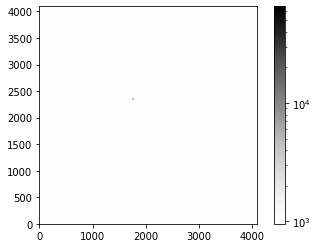

In [7]:
plt.figure()
plt.imshow(image_data,origin='lower',norm=LogNorm(),cmap='Greys')
plt.colorbar()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

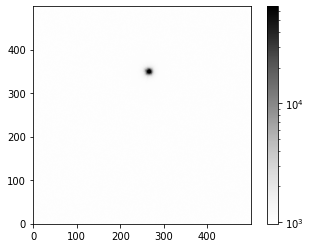

In [9]:
section1 = image_data[2000:2500, 1500:2000]
plt.figure()
plt.imshow(section1,origin='lower',norm=LogNorm(),cmap='Greys')
plt.colorbar()
plt.show

In [15]:
image_data=section1
mean,median,std=sigma_clipped_stats(image_data,sigma=3.0)

In [23]:
daofind=DAOStarFinder(fwhm=8.0,threshold=8.0*std) #FWHM = 8 is the size of a star in our image
sources=daofind(image_data-median)

for col in sources.colnames:
    if col not in ('id','npix'):
        sources[col].info.format='%.2f'
        
sources

id,xcentroid,ycentroid,sharpness,roundness1,roundness2,npix,sky,peak,flux,mag
int64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64
1,265.89,349.21,0.35,-0.38,-0.14,121,0.00,64514.00,1211.19,-7.71


In [17]:
positions=np.transpose((sources['xcentroid'],sources['ycentroid'])) #Because python does yx.
apertures = CircularAperture(positions,r=14.0) # This is the 1.5 FWHM as measured from the image using AIJ

In [27]:
annulus_aperture = CircularAnnulus(positions, r_in=25, r_out=38) # Set these to the ideal inner and outer apertures. 

<function matplotlib.pyplot.show(close=None, block=None)>

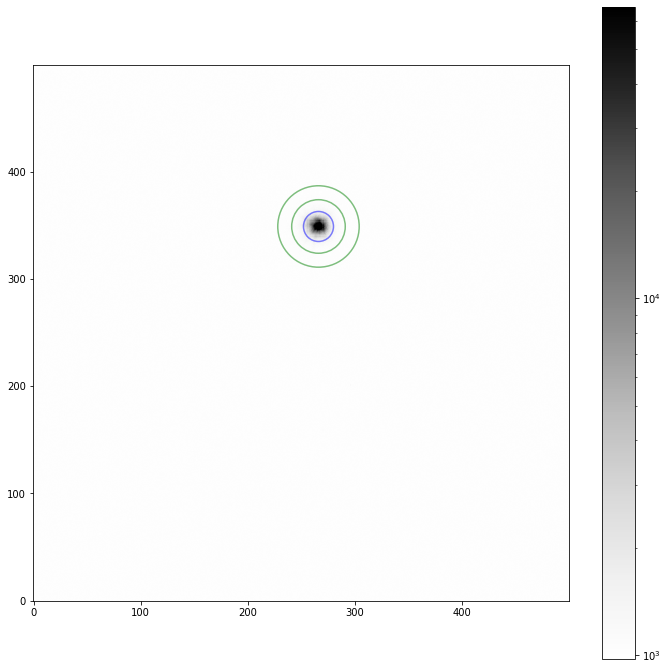

In [29]:
plt.figure(figsize=(12,12))
plt.imshow(image_data,origin='lower',norm=LogNorm(),cmap='Greys',interpolation = 'nearest')
apertures.plot(color='blue',lw=1.5,alpha=0.5);
annulus_aperture.plot(color='green',lw=1.5,alpha=0.5)
plt.colorbar()
plt.show

In [30]:
star_data = aperture_photometry(image_data,apertures)

In [32]:
bkg = aperture_photometry(image_data,annulus_aperture)
bkg_area = annulus_aperture.area_overlap(image_data)
aperture_area = apertures.area_overlap(image_data)
bkg_total = (bkg['aperture_sum']/bkg_area)*aperture_area #deals with different sizes of the apertures

In [33]:
star_data['total_bkg']=bkg_total
star_data['bkg_area']=bkg_area
star_data['aperture_area']=aperture_area
star_data['star_count']=star_data['aperture_sum']-star_data['total_bkg']


for col in star_data.colnames:
    star_data[col].info.format='%.8g'

star_data

id,xcenter,ycenter,aperture_sum,total_bkg,bkg_area,aperture_area,star_count
,pix,pix,,,,,
int64,float64,float64,float64,float64,float64,float64,float64
1,265.89245,349.20947,7325978.9,637915.74,2572.9644,615.75216,6688063.2
